## Visualizing exchanges within community

This script corresponds to the modeling of an MCF-7 community in co-culture with Fusobacterium nucleatum. In this part, the objetive was visualizing the exchanges within community.

#### Import packages and CSV file with fluxes

In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [11]:
fluxesTyF = pd.read_csv('TyF.csv', index_col=0) #load the ouput file that included all fluxes

In [4]:
fluxesTyF

,10FTHF5GLUtl,10FTHF5GLUtm,10FTHF6GLUtl,10FTHF6GLUtm,10FTHF7GLUtl,10FTHF7GLUtm,10FTHFtl,10FTHFtm,15DAPt,1PPDCRp,...,r2503,r2513,r2521,r2537,r2539,rtranscription,sink_citr_LPAREN_c_RPAREN_,sink_dmbzid,sink_s,xmpt
compartment,,,,,,,,,,,,,,,,,,,,,
CanA,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,...,NaN,-0.0,0.0,-0.0,NaN,NaN,NaN,NaN,NaN,0.000465
CanB,-0.0,-0.0,NaN,NaN,NaN,NaN,0.0,0.0,NaN,NaN,...,NaN,-0.0,NaN,-0.0,NaN,NaN,NaN,NaN,NaN,-0.000000
CanC,-0.0,-0.0,0.0,0.0,-0.0,-0.0,0.0,-0.0,NaN,-0.0,...,0.0,-0.0,NaN,-0.0,-0.0,NaN,0.027108,NaN,NaN,-0.000100
Fusobacterium,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,...,NaN,NaN,NaN,NaN,NaN,0.118586,NaN,0.0,0.0,NaN
medium,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### **Exchange reactions**

In [5]:
exchange_cols = fluxesTyF.columns[fluxesTyF.columns.str.startswith("EX_")] #Extract exchange fluxes

In [6]:
community_exchanges = fluxesTyF[exchange_cols]
community_exchanges_vertical = community_exchanges.reset_index().melt(
    id_vars="compartment", var_name="reaction", value_name="flux"
)
community_exchanges_nz = community_exchanges_vertical[
    community_exchanges_vertical["flux"] != 0
]
community_exchanges_vertical["type"] = community_exchanges_vertical["flux"].apply(
    lambda x: "consumed" if x < 0 else ("secreted" if x > 0 else "no flux")
)

In [7]:
community_exchanges_nz

,compartment,reaction,flux
0,CanA,EX_15dap_e,NaN
1,CanB,EX_15dap_e,NaN
2,CanC,EX_15dap_e,NaN
4,medium,EX_15dap_e,NaN
5,CanA,EX_15dap_m,NaN
...,...,...,...
2455,CanA,EX_zn2_m,NaN
2456,CanB,EX_zn2_m,NaN
2457,CanC,EX_zn2_m,NaN
2458,Fusobacterium,EX_zn2_m,NaN


#### Visualizing

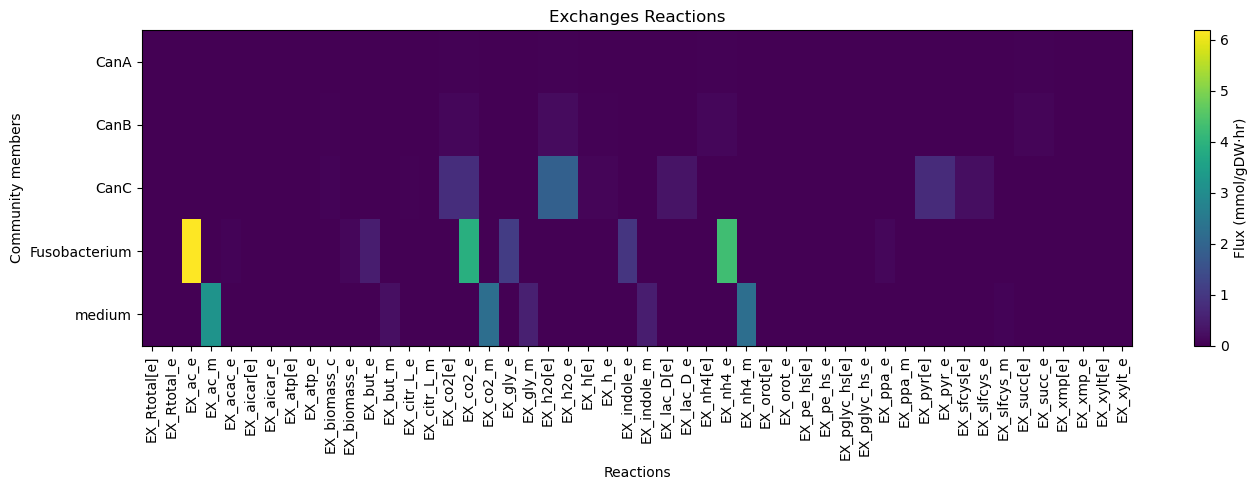

In [21]:
# Copy of original dataframe 
df = community_exchanges_nz.copy()

# Only secreted metabolites (flux > 0)
df_secreted = df[df["flux"] > 0].copy()

# heatmap
pivot = df_secreted.pivot_table(
    index="compartment",       # rows = species / taxon
    columns="reaction",   # columns = metabolites
    values="flux",        # value = secreted flux
    fill_value=0
)

# 
plt.figure(figsize=(14, 5))

#
plt.imshow(pivot, aspect="auto")

# Tags
plt.xticks(ticks=np.arange(len(pivot.columns)), labels=pivot.columns, rotation=90)
plt.yticks(ticks=np.arange(len(pivot.index)), labels=pivot.index)

plt.colorbar(label="Flux (mmol/gDW·hr)")
plt.title("Exchanges Reactions")
plt.xlabel("Reactions")
plt.ylabel("Community members")

plt.tight_layout()
plt.savefig("plots/reacciones_intercambio.png", dpi=300, bbox_inches="tight")
plt.show()

## **Exchange reactions within community: Exchanges dynamics**

In [9]:
ex_fluxes = fluxesTyF.loc[:, fluxesTyF.columns.str.startswith("EX_")]
ex_fluxes = ex_fluxes.copy()
ex_fluxes["compartment"] = ex_fluxes.index

# 
ex_long = ex_fluxes.melt(
    id_vars="compartment",
    var_name="reaction",
    value_name="flux"
)

#Filter non-zero fluxes
#ex_long = ex_long[ex_long["flux"] != 0] 

ex_long = ex_long[
    ex_long["flux"].notna() &
    (ex_long["flux"].abs() > 1e-9)]

# Consumed vs Secreted id 
ex_long["type"] = ex_long["flux"].apply(lambda x: "secreted" if x > 0 else "consumed")

# Name of metabolite 
ex_long["metabolite"] = (
    ex_long["reaction"]
    .str.replace("EX_", "", regex=False)
    .str.replace("_e", "", regex=False)
    .str.replace("[e]", "", regex=False)
)
# Identify exchange metabolites
secreted = ex_long[ex_long["type"] == "secreted"]
consumed = ex_long[ex_long["type"] == "consumed"]

exchanged = pd.merge(
    secreted,
    consumed,
    on="metabolite",
    suffixes=("_producer", "_consumer"),
    how="inner"
)

# Results
exchanged = exchanged[[
    "metabolite",
    "compartment_producer",
    "flux_producer",
    "compartment_consumer",
    "flux_consumer",
    "reaction_producer",
    "reaction_consumer"
]]

# Delete same compartment exchanges 
exchanged = exchanged[
    exchanged["compartment_producer"] !=
    exchanged["compartment_consumer"]
]

#
exchanged = exchanged.sort_values(
    ["metabolite", "compartment_producer", "compartment_consumer"]
).reset_index(drop=True)


print(exchanged)


   metabolite compartment_producer  flux_producer compartment_consumer  \
0      Rtotal                 CanC       0.015750                 CanA   
1      Rtotal                 CanC       0.015750                 CanA   
2      Rtotal                 CanC       0.015750                 CanA   
3      Rtotal                 CanC       0.015750                 CanA   
4      Rtotal                 CanC       0.015750                 CanB   
..        ...                  ...            ...                  ...   
77        xmp                 CanC       0.000100                 CanA   
78       xylt                 CanC       0.000885                 CanA   
79       xylt                 CanC       0.000885                 CanA   
80       xylt                 CanC       0.000885                 CanA   
81       xylt                 CanC       0.000885                 CanA   

    flux_consumer reaction_producer reaction_consumer  
0       -0.004162      EX_Rtotal[e]      EX_Rtotal[e]  

In [10]:
exchanged.to_csv("exchanges_complete_2.csv") #this dataframe include all the exchanges reactions.

In [12]:
import pandas as pd

# ============================================================
# CONFIGURACIÓN
# ============================================================

# Umbral para considerar que existe un flujo real
TOL = 1e-9

# Nombre que debe tener el compartimento del medio
MEDIUM_NAME = "medium"


# ============================================================
# 1. EXTRAER REACCIONES DE INTERCAMBIO
# ============================================================

ex_fluxes = fluxesTyF.loc[
    :, fluxesTyF.columns.str.startswith("EX_")
].copy()

# El índice contiene el organismo/compartimento
ex_fluxes["compartment"] = ex_fluxes.index


# ============================================================
# 2. FORMATO LARGO
# ============================================================

ex_long = ex_fluxes.melt(
    id_vars="compartment",
    var_name="reaction",
    value_name="flux"
)


# ============================================================
# 3. LIMPIAR FLUJOS
# ============================================================

ex_long = ex_long[
    ex_long["flux"].notna() &
    (ex_long["flux"].abs() > TOL)
].copy()


# ============================================================
# 4. IDENTIFICAR EL METABOLITO
# ============================================================

ex_long["metabolite"] = (
    ex_long["reaction"]
    .str.replace("EX_", "", regex=False)
    .str.replace("_e", "", regex=False)
    .str.replace("[e]", "", regex=False)
)


# ============================================================
# 5. CLASIFICAR DIRECCIÓN
# ============================================================

# + flujo = secreción
# - flujo = consumo

ex_long["type"] = ex_long["flux"].apply(
    lambda x: "secreted" if x > 0 else "consumed"
)

# Magnitud del flujo
ex_long["flux_abs"] = ex_long["flux"].abs()


# ============================================================
# 6. TABLA 1: MEDIUM UPTAKE
# ============================================================

medium_uptake = ex_long[
    (ex_long["compartment"] != MEDIUM_NAME) &
    (ex_long["type"] == "consumed")
].copy()

medium_uptake["interaction"] = (
    MEDIUM_NAME + " → " +
    medium_uptake["compartment"]
)

medium_uptake = medium_uptake[[
    "metabolite",
    "compartment",
    "reaction",
    "flux",
    "flux_abs",
    "interaction"
]].sort_values(
    ["metabolite", "compartment"]
).reset_index(drop=True)


# ============================================================
# 7. TABLA 2: MEDIUM SECRETION
# ============================================================

medium_secretion = ex_long[
    (ex_long["compartment"] != MEDIUM_NAME) &
    (ex_long["type"] == "secreted")
].copy()

medium_secretion["interaction"] = (
    medium_secretion["compartment"] +
    " → " + MEDIUM_NAME
)

medium_secretion = medium_secretion[[
    "metabolite",
    "compartment",
    "reaction",
    "flux",
    "flux_abs",
    "interaction"
]].sort_values(
    ["metabolite", "compartment"]
).reset_index(drop=True)


# ============================================================
# 8. PRODUCTORES Y CONSUMIDORES
# ============================================================

secreted = ex_long[
    ex_long["type"] == "secreted"
].copy()

consumed = ex_long[
    ex_long["type"] == "consumed"
].copy()


# ============================================================
# 9. TABLA 3: ORGANISM-ORGANISM CROSS-FEEDING
# ============================================================

crossfeeding = pd.merge(
    secreted,
    consumed,
    on="metabolite",
    suffixes=("_producer", "_consumer"),
    how="inner"
)


# ------------------------------------------------------------
# Eliminar el medio como productor o consumidor
# ------------------------------------------------------------

#crossfeeding = crossfeeding[
    #(crossfeeding["compartment_producer"] != MEDIUM_NAME) &
    #(crossfeeding["compartment_consumer"] != MEDIUM_NAME)
#]


# ------------------------------------------------------------
# Evitar que un organismo aparezca como su propio consumidor
# ------------------------------------------------------------

crossfeeding = crossfeeding[
    crossfeeding["compartment_producer"] !=
    crossfeeding["compartment_consumer"]
]


# ============================================================
# 10. COLUMNAS FINALES
# ============================================================

crossfeeding["flux_producer_abs"] = (
    crossfeeding["flux_producer"].abs()
)

crossfeeding["flux_consumer_abs"] = (
    crossfeeding["flux_consumer"].abs()
)

crossfeeding["interaction"] = (
    crossfeeding["compartment_producer"] +
    " → " +
    crossfeeding["metabolite"] +
    " → " +
    crossfeeding["compartment_consumer"]
)

crossfeeding = crossfeeding[[
    "metabolite",
    "compartment_producer",
    "flux_producer",
    "flux_producer_abs",
    "compartment_consumer",
    "flux_consumer",
    "flux_consumer_abs",
    "reaction_producer",
    "reaction_consumer",
    "interaction"
]].sort_values(
    ["metabolite",
     "compartment_producer",
     "compartment_consumer"]
).reset_index(drop=True)


# ============================================================
# 11. MOSTRAR RESULTADOS
# ============================================================

print("\n" + "="*70)
print("MEDIUM UPTAKE")
print("="*70)
print(medium_uptake.to_string(index=False))

print("\n" + "="*70)
print("MEDIUM SECRETION")
print("="*70)
print(medium_secretion.to_string(index=False))

print("\n" + "="*70)
print("ORGANISM-ORGANISM CROSS-FEEDING")
print("="*70)
print(crossfeeding.to_string(index=False))


MEDIUM UPTAKE
metabolite   compartment       reaction      flux  flux_abs            interaction
    Rtotal          CanA   EX_Rtotal[e] -0.004162  0.004162          medium → CanA
    Rtotal          CanA    EX_Rtotal_e -0.004162  0.004162          medium → CanA
    Rtotal          CanB   EX_Rtotal[e] -0.017207  0.017207          medium → CanB
    Rtotal          CanB    EX_Rtotal_e -0.017207  0.017207          medium → CanB
      acac          CanC     EX_acac[e] -0.136631  0.136631          medium → CanC
      acac          CanC      EX_acac_e -0.136631  0.136631          medium → CanC
     aicar          CanB    EX_aicar[e] -0.004734  0.004734          medium → CanB
     aicar          CanB     EX_aicar_e -0.004734  0.004734          medium → CanB
     ala_L          CanA    EX_ala_L[e] -0.002108  0.002108          medium → CanA
     ala_L          CanA     EX_ala_L_e -0.002108  0.002108          medium → CanA
     ala_L          CanB    EX_ala_L[e] -0.020448  0.020448          med

In [14]:
crossfeeding.to_csv("croos_feeding.csv") #this dataframe include all the exchanges reactions.

### Vizualizing

In [6]:
exchanges_complete = pd.read_csv('croos_feeding.csv', index_col=0) #this dataframe exclude reactions like h2o, h, biomass, co2

In [7]:
exchanges_complete

,metabolite,compartment_producer,flux_producer,flux_producer_abs,compartment_consumer,flux_consumer,flux_consumer_abs,reaction_producer,reaction_consumer,interaction
0,Rtotal,CanC,0.015750,0.015750,CanA,-0.004162,0.004162,EX_Rtotal[e],EX_Rtotal[e],CanC → Rtotal → CanA
1,Rtotal,CanC,0.015750,0.015750,CanA,-0.004162,0.004162,EX_Rtotal[e],EX_Rtotal_e,CanC → Rtotal → CanA
2,Rtotal,CanC,0.015750,0.015750,CanA,-0.004162,0.004162,EX_Rtotal_e,EX_Rtotal[e],CanC → Rtotal → CanA
3,Rtotal,CanC,0.015750,0.015750,CanA,-0.004162,0.004162,EX_Rtotal_e,EX_Rtotal_e,CanC → Rtotal → CanA
4,Rtotal,CanC,0.015750,0.015750,CanB,-0.017207,0.017207,EX_Rtotal[e],EX_Rtotal[e],CanC → Rtotal → CanB
...,...,...,...,...,...,...,...,...,...,...
77,xmp,CanC,0.000100,0.000100,CanA,-0.000465,0.000465,EX_xmp_e,EX_xmp_e,CanC → xmp → CanA
78,xylt,CanC,0.000885,0.000885,CanA,-0.004105,0.004105,EX_xylt[e],EX_xylt[e],CanC → xylt → CanA
79,xylt,CanC,0.000885,0.000885,CanA,-0.004105,0.004105,EX_xylt[e],EX_xylt_e,CanC → xylt → CanA
80,xylt,CanC,0.000885,0.000885,CanA,-0.004105,0.004105,EX_xylt_e,EX_xylt[e],CanC → xylt → CanA


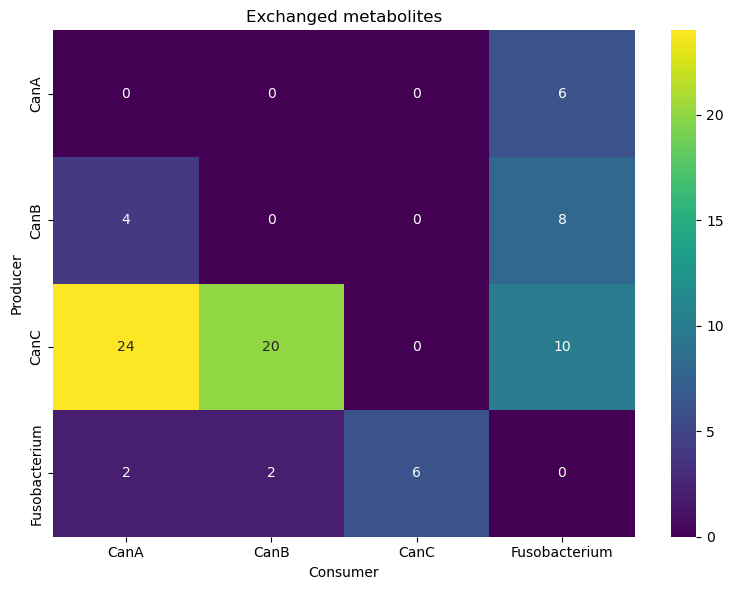

In [13]:
# Make a matrix specie-producer vs specie-consumer 
#without h20, h, biomass,  Rtotal
matrix = exchanges_complete.groupby(
    ["compartment_producer", "compartment_consumer"]
).size().unstack(fill_value=0)

plt.figure(figsize=(8,6))
sns.heatmap(matrix, annot=True, fmt="d", cmap="viridis")
plt.title("Exchanged metabolites")
plt.xlabel("Consumer")
plt.ylabel("Producer")
plt.tight_layout()
plt.savefig("plots/intercambio_metabolitos_NUEVO.png", dpi=300, bbox_inches="tight")
plt.show()

#### **Add magnitude**

In [14]:
exchanges_complete["magnitude"] = exchanges_complete[["flux_producer", "flux_consumer"]].abs().max(axis=1)

In [15]:
exchanges_complete.sort_values("magnitude", ascending=False) 

,metabolite,compartment_producer,flux_producer,flux_producer_abs,compartment_consumer,flux_consumer,flux_consumer_abs,reaction_producer,reaction_consumer,interaction,magnitude
31,h2o,CanA,0.035497,0.035497,Fusobacterium,-2.307809,2.307809,EX_h2o_e,EX_h2o_e,CanA → h2o → Fusobacterium,2.307809
30,h2o,CanA,0.035497,0.035497,Fusobacterium,-2.307809,2.307809,EX_h2o[e],EX_h2o_e,CanA → h2o → Fusobacterium,2.307809
33,h2o,CanB,0.182631,0.182631,Fusobacterium,-2.307809,2.307809,EX_h2o_e,EX_h2o_e,CanB → h2o → Fusobacterium,2.307809
32,h2o,CanB,0.182631,0.182631,Fusobacterium,-2.307809,2.307809,EX_h2o[e],EX_h2o_e,CanB → h2o → Fusobacterium,2.307809
34,h2o,CanC,1.928792,1.928792,Fusobacterium,-2.307809,2.307809,EX_h2o[e],EX_h2o_e,CanC → h2o → Fusobacterium,2.307809
...,...,...,...,...,...,...,...,...,...,...,...
57,pglyc_hs,CanC,0.000540,0.000540,CanA,-0.000147,0.000147,EX_pglyc_hs_e,EX_pglyc_hs_e,CanC → pglyc_hs → CanA,0.000540
77,xmp,CanC,0.000100,0.000100,CanA,-0.000465,0.000465,EX_xmp_e,EX_xmp_e,CanC → xmp → CanA,0.000465
76,xmp,CanC,0.000100,0.000100,CanA,-0.000465,0.000465,EX_xmp_e,EX_xmp[e],CanC → xmp → CanA,0.000465
75,xmp,CanC,0.000100,0.000100,CanA,-0.000465,0.000465,EX_xmp[e],EX_xmp_e,CanC → xmp → CanA,0.000465


#### **Change magnitude to percentage**

In [16]:
exchanges_complete["percentage"] = (
    exchanges_complete["magnitude"] /
    exchanges_complete.groupby("compartment_producer")["magnitude"].transform("sum")
) * 100

In [17]:
exchanges_complete

,metabolite,compartment_producer,flux_producer,flux_producer_abs,compartment_consumer,flux_consumer,flux_consumer_abs,reaction_producer,reaction_consumer,interaction,magnitude,percentage
0,Rtotal,CanC,0.015750,0.015750,CanA,-0.004162,0.004162,EX_Rtotal[e],EX_Rtotal[e],CanC → Rtotal → CanA,0.015750,0.184179
1,Rtotal,CanC,0.015750,0.015750,CanA,-0.004162,0.004162,EX_Rtotal[e],EX_Rtotal_e,CanC → Rtotal → CanA,0.015750,0.184179
2,Rtotal,CanC,0.015750,0.015750,CanA,-0.004162,0.004162,EX_Rtotal_e,EX_Rtotal[e],CanC → Rtotal → CanA,0.015750,0.184179
3,Rtotal,CanC,0.015750,0.015750,CanA,-0.004162,0.004162,EX_Rtotal_e,EX_Rtotal_e,CanC → Rtotal → CanA,0.015750,0.184179
4,Rtotal,CanC,0.015750,0.015750,CanB,-0.017207,0.017207,EX_Rtotal[e],EX_Rtotal[e],CanC → Rtotal → CanB,0.017207,0.201222
...,...,...,...,...,...,...,...,...,...,...,...,...
77,xmp,CanC,0.000100,0.000100,CanA,-0.000465,0.000465,EX_xmp_e,EX_xmp_e,CanC → xmp → CanA,0.000465,0.005437
78,xylt,CanC,0.000885,0.000885,CanA,-0.004105,0.004105,EX_xylt[e],EX_xylt[e],CanC → xylt → CanA,0.004105,0.048008
79,xylt,CanC,0.000885,0.000885,CanA,-0.004105,0.004105,EX_xylt[e],EX_xylt_e,CanC → xylt → CanA,0.004105,0.048008
80,xylt,CanC,0.000885,0.000885,CanA,-0.004105,0.004105,EX_xylt_e,EX_xylt[e],CanC → xylt → CanA,0.004105,0.048008


In [10]:
exchanges_complete.groupby("metabolite")["percentage"].sum().sort_values(ascending=False) #see the percentage distribution

metabolite
pyr         99.157467
nh4         96.024138
succ        92.569602
ac_m        46.843559
ac          38.247742
nh4_m       32.830799
lac_D       24.992015
gly         20.332562
gly_m        8.165565
indole       7.943909
indole_m     7.296920
sfcys        4.692443
slfcys       4.692443
but          4.025572
but_m        3.697711
ppa          2.086690
xylt         1.210317
citr_L       1.164818
slfcys_m     0.828777
acac         0.815327
orot         0.749683
aicar        0.554621
pe_hs        0.362845
atp          0.254230
ppa_m        0.233804
citr_L_m     0.102865
pglyc_hs     0.094982
xmp          0.028596
Name: percentage, dtype: float64

In [18]:
exchanges_complete.to_csv("EXCHANGES_FILES/exchanges_Nuevo_analisis.csv") #save the dataframe for vizualizing in ggplot2

In [13]:
exchanges_complete[exchanges_complete["percentage"] > 2] # Only percentage > 2

,compartment_producer,flux_producer,compartment_consumer,flux_consumer,magnitude,percentage
metabolite,,,,,,
ac,Fusobacterium,6.188380,Fusobacterium,NaN,6.188380,12.749247
ac,Fusobacterium,6.188380,medium,NaN,6.188380,12.749247
ac,Fusobacterium,6.188380,medium,NaN,6.188380,12.749247
ac_m,medium,3.187094,CanA,NaN,3.187094,11.710890
ac_m,medium,3.187094,CanB,NaN,3.187094,11.710890
...,...,...,...,...,...,...
succ,CanB,0.080236,Fusobacterium,NaN,0.080236,3.897464
succ,CanA,0.024566,medium,NaN,0.024566,6.454836
succ,CanA,0.024566,Fusobacterium,-0.040094,0.040094,10.534853


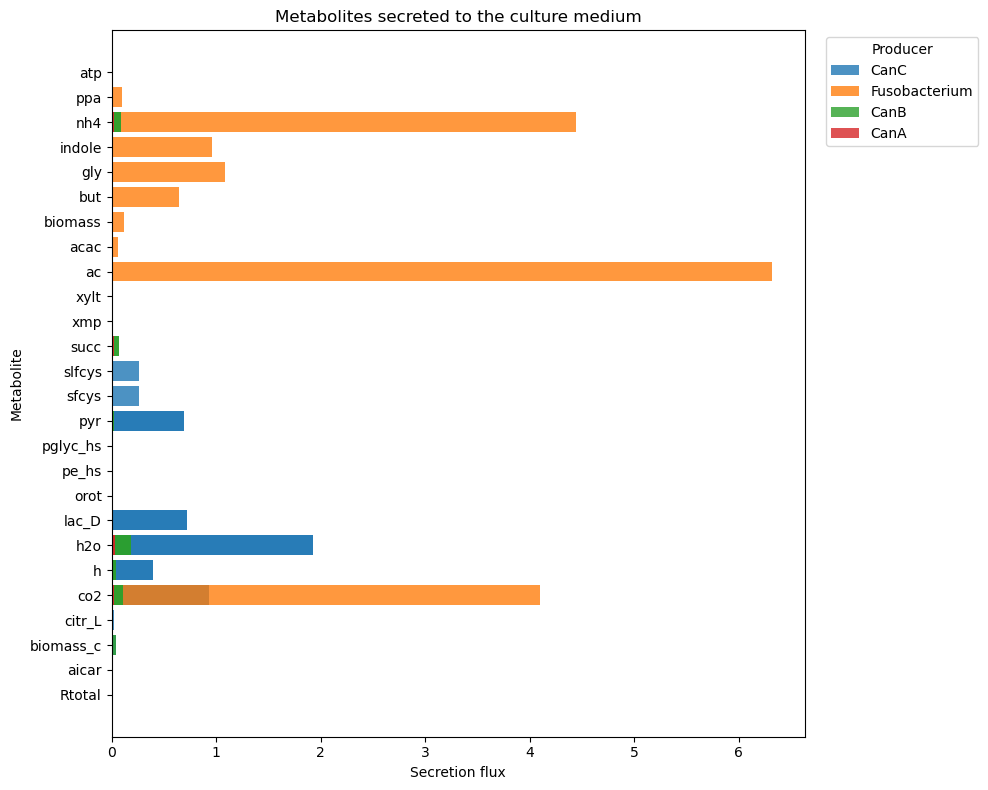

In [19]:
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# 1. Preparar datos
# ============================================================

plot_data = medium_secretion.copy()

# Usamos la magnitud positiva del flujo
plot_data["flux_plot"] = plot_data["flux"].abs()

# ============================================================
# 2. Ordenar metabolitos por secreción total
# ============================================================

metabolite_order = (
    plot_data
    .groupby("metabolite")["flux_plot"]
    .sum()
    .sort_values(ascending=True)
    .index
)

plot_data["metabolite"] = pd.Categorical(
    plot_data["metabolite"],
    categories=metabolite_order,
    ordered=True
)

# ============================================================
# 3. Graficar
# ============================================================

fig, ax = plt.subplots(figsize=(10, 8))

for organism in plot_data["compartment"].unique():

    data = plot_data[
        plot_data["compartment"] == organism
    ]

    ax.barh(
        data["metabolite"],
        data["flux_plot"],
        label=organism,
        alpha=0.8
    )

# ============================================================
# 4. Formato
# ============================================================

ax.set_xlabel("Secretion flux")
ax.set_ylabel("Metabolite")
ax.set_title("Metabolites secreted to the culture medium")

ax.legend(
    title="Producer",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

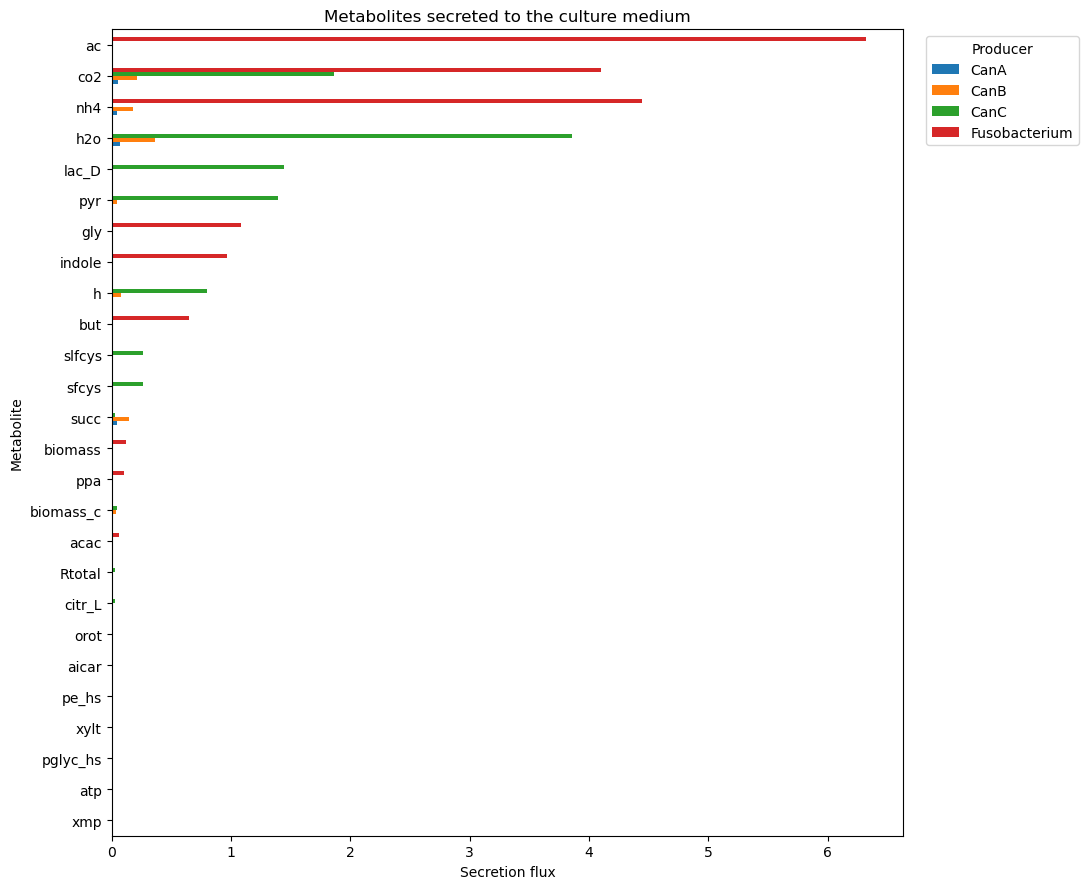

In [20]:
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# 1. Preparar datos
# ============================================================

plot_data = medium_secretion.copy()

plot_data["flux_plot"] = plot_data["flux"].abs()

# ============================================================
# 2. Convertir a formato ancho
# ============================================================

plot_wide = plot_data.pivot_table(
    index="metabolite",
    columns="compartment",
    values="flux_plot",
    aggfunc="sum",
    fill_value=0
)

# ============================================================
# 3. Ordenar por secreción total
# ============================================================

plot_wide["total"] = plot_wide.sum(axis=1)

plot_wide = plot_wide.sort_values("total")

plot_wide = plot_wide.drop(columns="total")


# ============================================================
# 4. Graficar
# ============================================================

ax = plot_wide.plot(
    kind="barh",
    figsize=(11, 9)
)

ax.set_xlabel("Secretion flux")
ax.set_ylabel("Metabolite")
ax.set_title("Metabolites secreted to the culture medium")

ax.legend(
    title="Producer",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

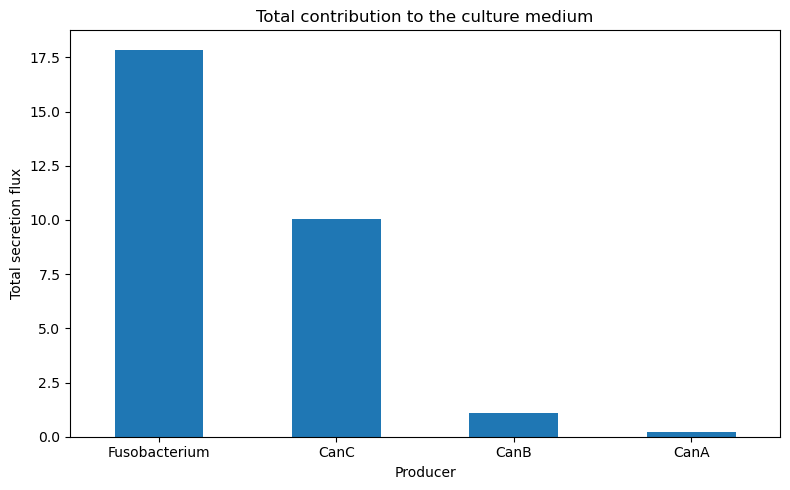

In [21]:
# Flujo total secretado por organismo
total_secretion = (
    medium_secretion
    .groupby("compartment")["flux_abs"]
    .sum()
    .sort_values(ascending=False)
)

ax = total_secretion.plot(
    kind="bar",
    figsize=(8, 5)
)

ax.set_xlabel("Producer")
ax.set_ylabel("Total secretion flux")
ax.set_title("Total contribution to the culture medium")

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()